In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

##import os
##for dirname, _, filenames in os.walk('/kaggle/input'):
##    for filename in filenames:
##        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import warnings
warnings.filterwarnings('ignore')




In [3]:
paths =[]
labels = []
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        paths.append(os.path.join(dirname, filename))
        label = filename.split('_')[-1]
        label = label.split('.')[0]
        labels.append(label.lower())
print("dataset is loaded")
        

dataset is loaded


In [4]:
paths[:5]

['/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear/OAF_back_fear.wav',
 '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear/OAF_bar_fear.wav',
 '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear/OAF_base_fear.wav',
 '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear/OAF_bath_fear.wav',
 '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear/OAF_bean_fear.wav']

In [5]:
labels[:5]

['fear', 'fear', 'fear', 'fear', 'fear']

In [6]:
# create a data frame
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels
df.head()

,speech,label
0,/kaggle/input/datasets/ejlok1/toronto-emotiona...,fear
1,/kaggle/input/datasets/ejlok1/toronto-emotiona...,fear
2,/kaggle/input/datasets/ejlok1/toronto-emotiona...,fear
3,/kaggle/input/datasets/ejlok1/toronto-emotiona...,fear
4,/kaggle/input/datasets/ejlok1/toronto-emotiona...,fear


In [7]:
df['label'].value_counts()

label
fear       800
ps         800
sad        800
angry      800
disgust    800
happy      800
neutral    800
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='label'>

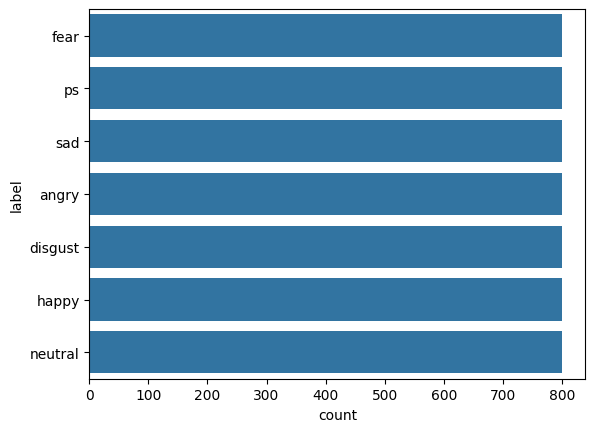

In [8]:
sns.countplot(df["label"])

In [9]:
def waveplot(data, sr, emotion):
    plt.figure(figsize = (10, 4))
    plt.title(emotion, size = 20)
    librosa.display.waveshow(data, sr = sr)
    plt.show()
def spectogram(data, sr, emotion):
    x = librosa.stft(data)
    xdb = librosa.amplitude_to_db(abs(x))
    plt.figure(figsize = (11, 4))
    plt.title(emotion, size = 20)
    librosa.display.specshow(xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()

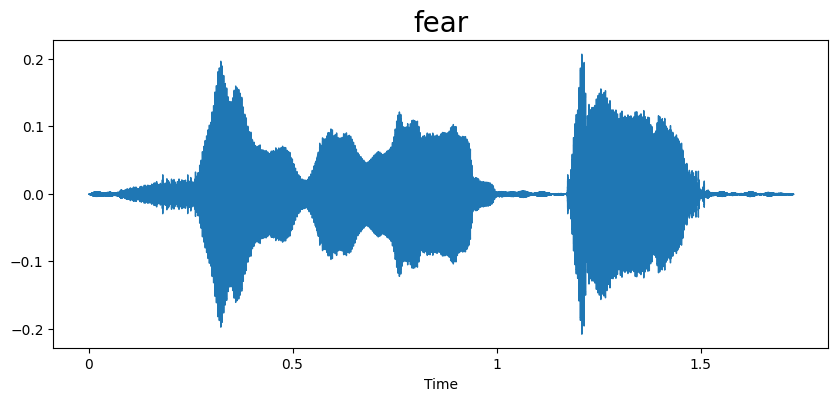

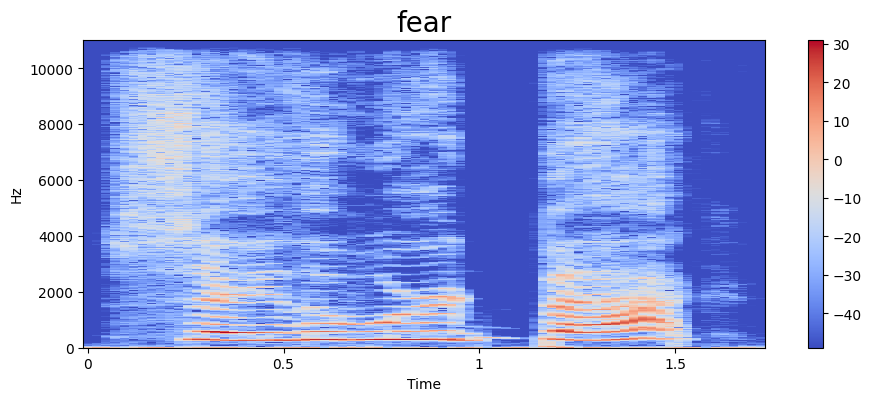

In [10]:
emotion = 'fear'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

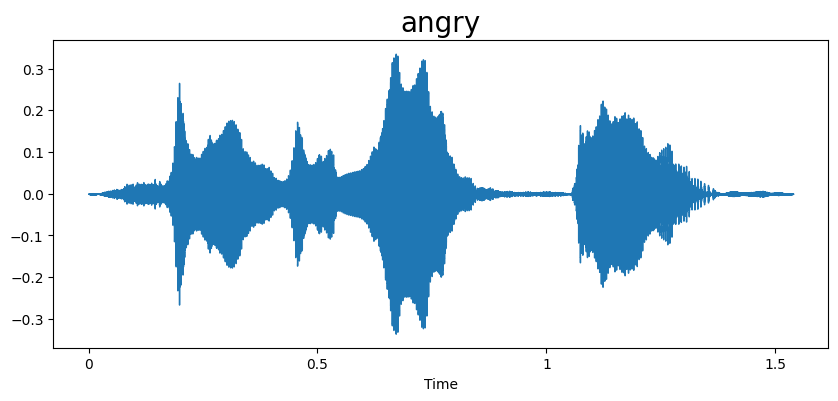

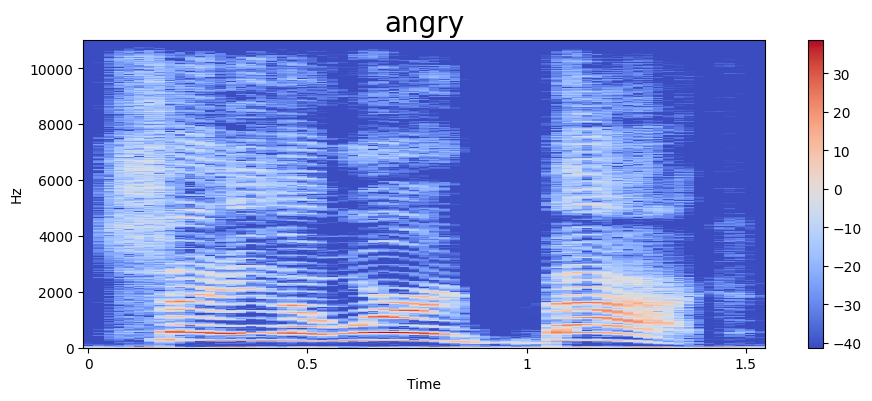

In [11]:
emotion = 'angry'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

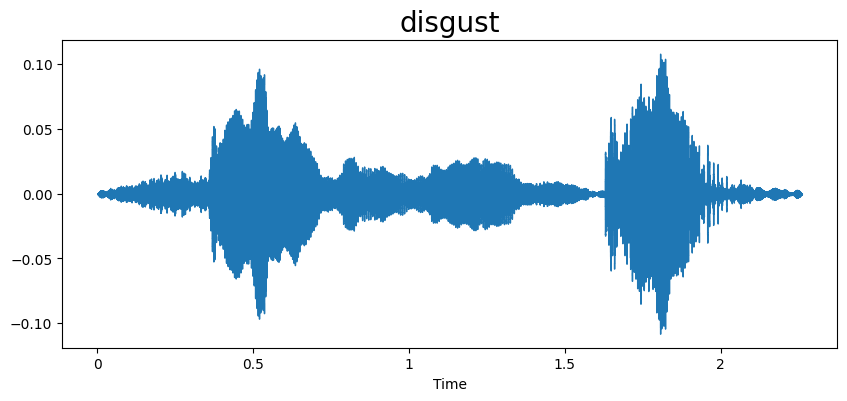

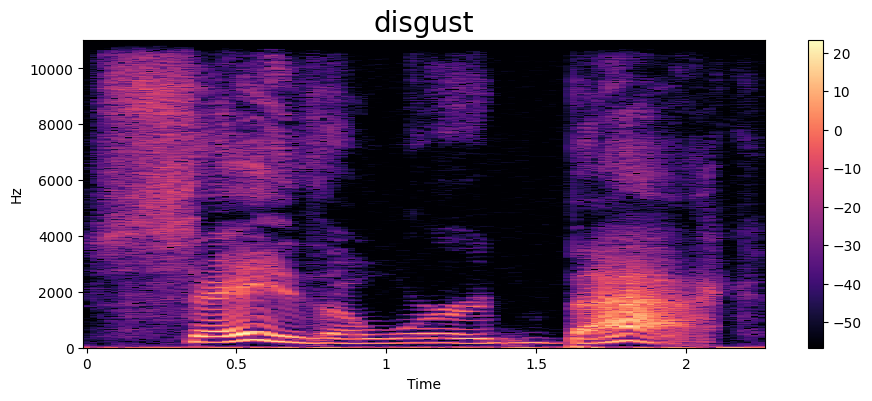

In [12]:
emotion = 'disgust'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

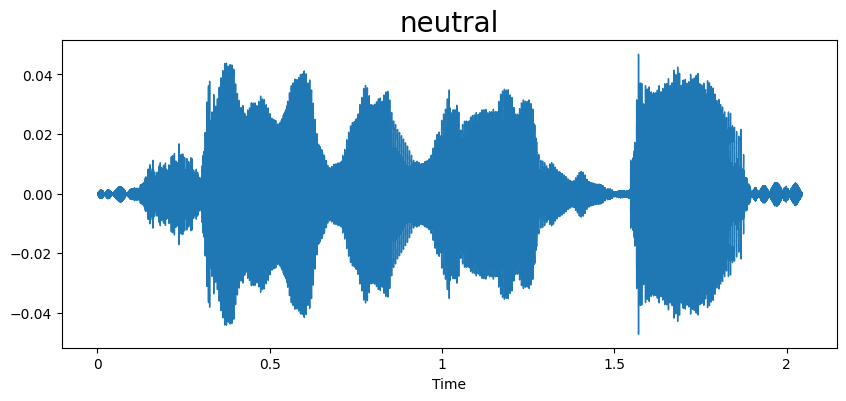

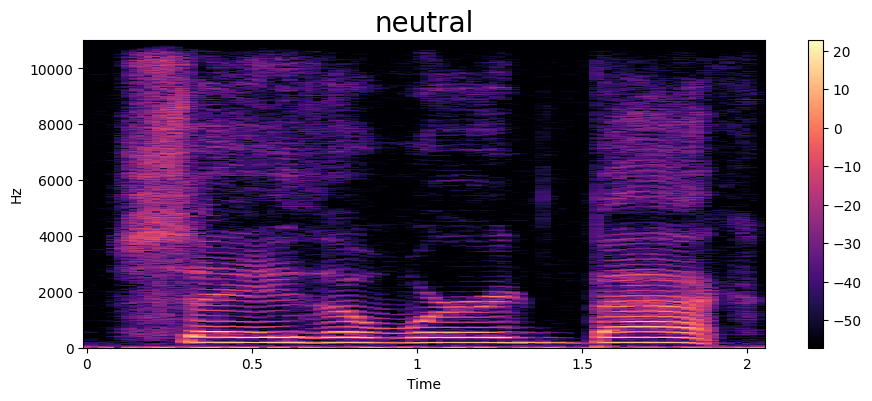

In [13]:
emotion = 'neutral'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

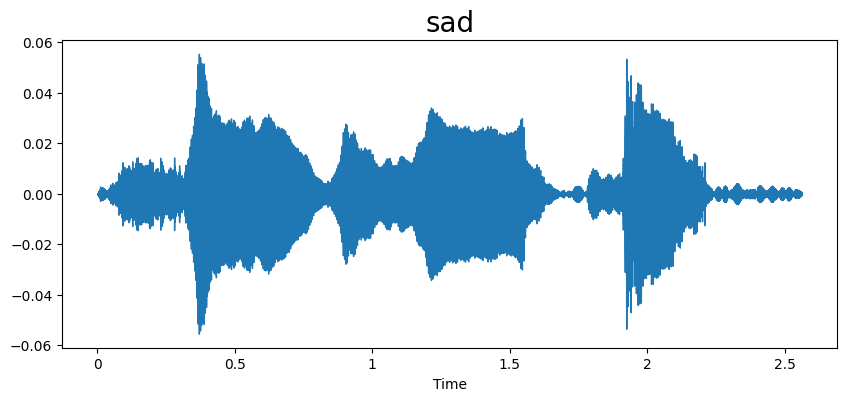

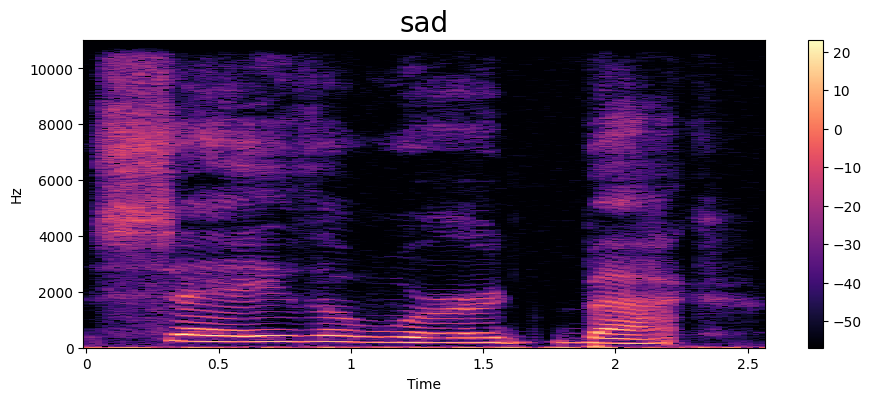

In [14]:
emotion = 'sad'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

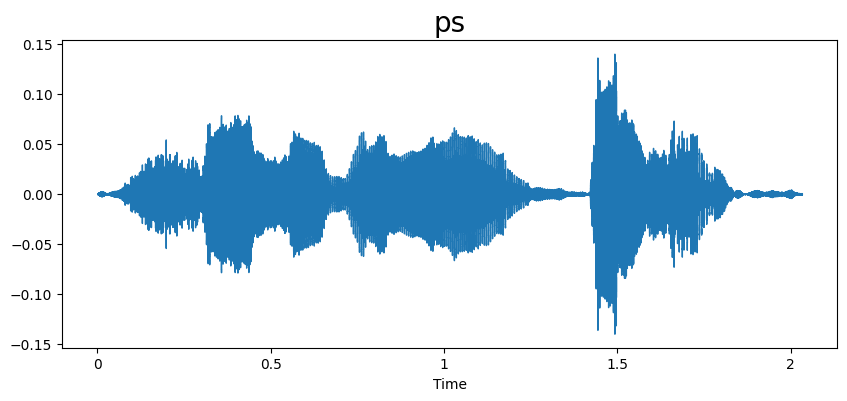

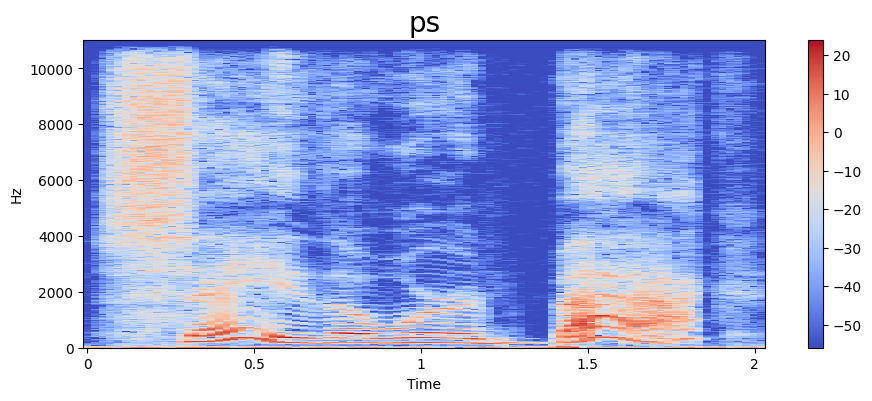

In [15]:
emotion = 'ps'
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

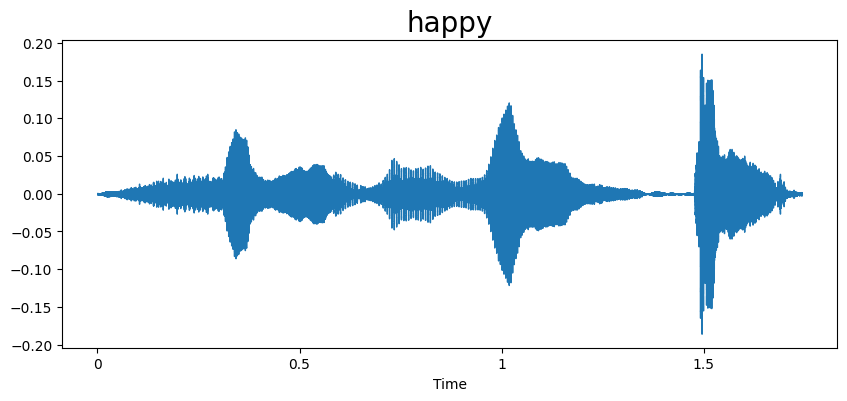

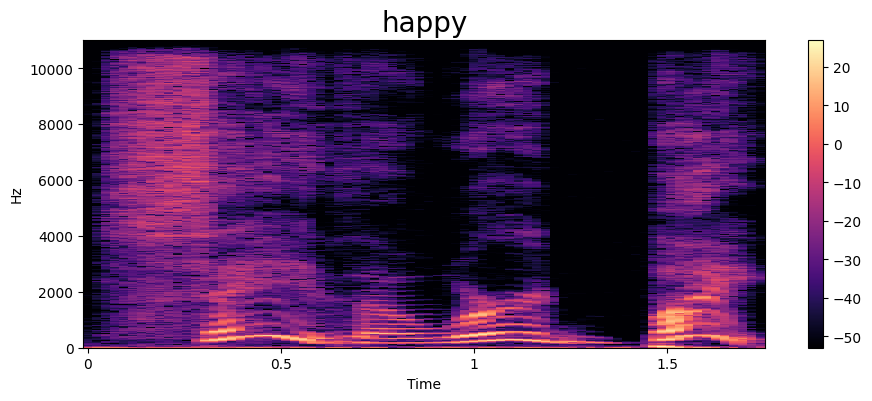

In [16]:
emotion = 'happy'
path = np.array(df['speech'][df['label']==emotion])[6]
data, sampling_rate = librosa.load(path)
waveplot(data, sampling_rate, emotion)
spectogram(data, sampling_rate,emotion)
Audio(path)

In [17]:
def extract_mfcc(filename):
    y,sr = librosa.load(filename,duration = 3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y,sr=sr, n_mfcc=40).T, axis=0)
    return mfcc
    

In [18]:
extract_mfcc(df['speech'][0])

array([-4.4536740e+02,  9.1276093e+01, -5.8949256e-01, -1.7314268e+01,
        3.2114537e+00,  3.8689072e+00, -1.2856502e+01, -3.4997500e-02,
       -1.0514208e+01,  1.8963062e+00, -1.3004948e+01, -7.5758567e+00,
       -6.3761392e+00, -3.0671544e+00, -2.8966854e+00,  2.5014248e+00,
       -6.5666776e+00,  2.3161004e+00,  3.9002411e+00, -7.2122092e+00,
        6.1384773e+00,  1.8507450e+01,  1.5220100e+01,  2.9525787e+01,
        2.1546635e+01,  1.7631252e+01,  7.3770428e+00,  2.2608621e+00,
       -2.9354751e+00,  6.0986023e+00,  5.5288827e-01,  2.1243875e+00,
       -2.8407288e+00, -4.6624756e+00,  8.0207396e-01,  3.1533179e+00,
       -2.4966443e+00, -1.1518220e+00, -2.2240906e+00,  2.2110424e+00],
      dtype=float32)

In [19]:
x_mfcc =df['speech'].apply(lambda x: extract_mfcc(x))

In [20]:
x_mfcc

0       [-445.3674, 91.27609, -0.58949256, -17.314268,...
1       [-456.2984, 95.33353, 17.716852, -33.76581, -1...
2       [-461.2538, 56.51359, 13.97067, 2.563785, 8.11...
3       [-412.7426, 85.44517, 7.6585965, -21.482409, -...
4       [-499.1559, 72.94784, 25.2297, 8.166257, 11.47...
                              ...                        
5595    [-406.48056, 80.37989, 32.462395, 46.5791, -1....
5596    [-426.90918, 102.54757, 24.800041, 43.0481, 4....
5597    [-378.50494, 80.910614, 35.300533, 39.74792, -...
5598    [-434.86185, 89.90639, 28.37326, 39.577065, -2...
5599    [-421.83417, 70.69788, 32.476395, 45.642555, 4...
Name: speech, Length: 5600, dtype: object

In [21]:
x = [x for x in x_mfcc]
x = np.array(x)
x.shape

(5600, 40)

In [22]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder()  # returns a NumPy array directly
y = enc.fit_transform(df[['label']])

In [23]:
y= y.toarray()

In [24]:
y.shape

(5600, 7)

/[](http://)*[](http://) create the LSTM Model****

In [25]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout


model = Sequential([
    LSTM(123, return_sequences= False, input_shape= (40,1)),
    Dense(64, activation ='relu'),
    Dropout(0.2),
    Dense(32,activation='relu'),
    Dropout(0.2),
    Dense(7,activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 123)            │        61,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         7,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,747 (280.26 KB)

 Trainable params: 71,747 (280.26 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Train the model
history = model.fit(x, y, validation_split=0.2,epochs=100,batch_size=512,shuffle=True)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.2558 - loss: 1.8562 - val_accuracy: 0.1187 - val_loss: 1.8360
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4435 - loss: 1.5911 - val_accuracy: 0.3705 - val_loss: 1.5568
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5752 - loss: 1.2369 - val_accuracy: 0.5786 - val_loss: 1.0527
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6732 - loss: 0.9086 - val_accuracy: 0.7036 - val_loss: 0.7487
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7366 - loss: 0.7093 - val_accuracy: 0.7920 - val_loss: 0.5278
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7904 - loss: 0.5707 - val_accuracy: 0.8616 - val_loss: 0.3656
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8491 - loss: 0.4427 - val_accuracy: 0.9411 - val_loss: 0.2436
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8958 - loss: 0.3279 - val_accuracy: 0.9518 - val_loss:

**Plot the  results

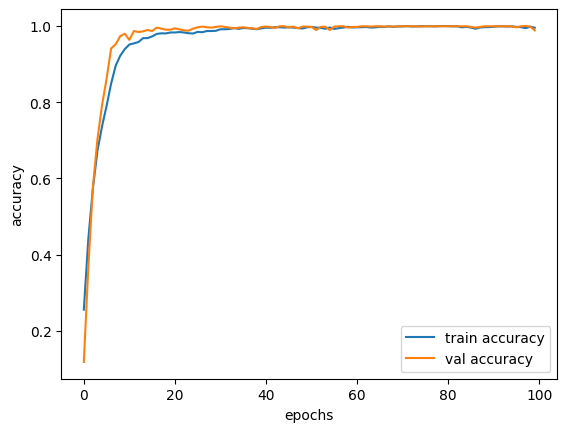

In [27]:
epochs = list(range(100))

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.plot(epochs, acc, label = 'train accuracy')
plt.plot(epochs, val_acc, label = 'val accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

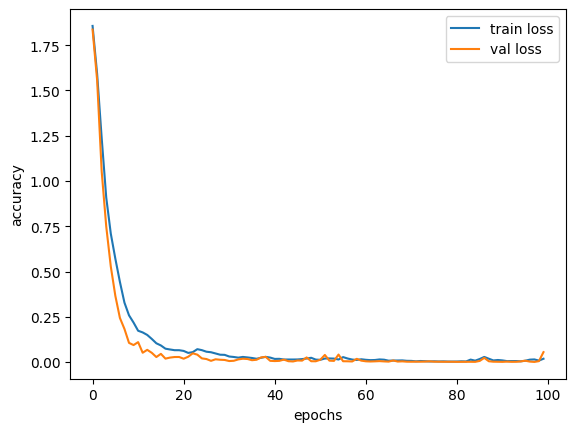

In [28]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs, loss, label = 'train loss')
plt.plot(epochs, val_loss, label = 'val loss')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()